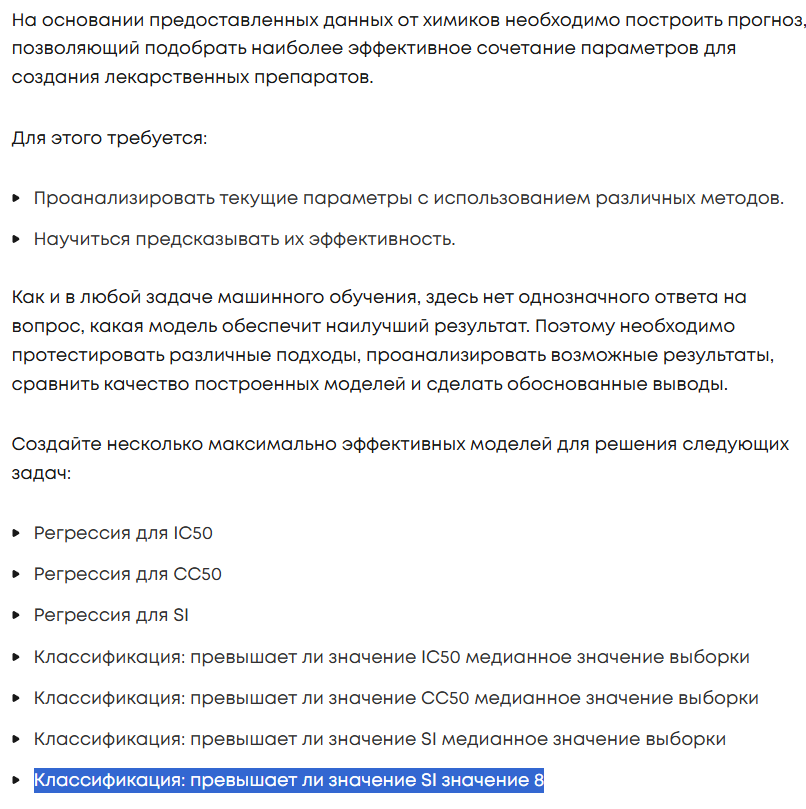

??????????

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, confusion_matrix, precision_recall_curve
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

import warnings
warnings.filterwarnings('ignore')

In [ ]:
data = pd.read_csv('important_features_for_SI.csv')

In [ ]:
# ???????? ???????? ??????? ?????????? (1 ???? SI > 8, ????? 0)
y = (data['SI'] > 8).astype(int)
X = data.drop('SI', axis=1)

# ???????? ??????? ???????
print("????????????? ???????:")
print(y.value_counts(normalize=True))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)


])

?????????????

In [ ]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object', 'category']).columns

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)

In [ ]:
# ??????? ??????? t/f
def evaluate_model(model, model_name, X_train, X_test, y_train, y_test):
    print(f"\n{'-'*50}")
    print(f"?????? ?????? {model_name}")
    print(f"{'-'*50}")
    
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:,1]
    
    # ???????
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")
    
    # ?????-?????????
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc')
    print(f"CV ROC-AUC: {cv_scores.mean():.4f} ? {cv_scores.std():.4f}")
    
    # ??????? ??????
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['SI ? 8', 'SI > 8'], 
                yticklabels=['SI ? 8', 'SI > 8'])
    plt.title(f'??????? ?????? ({model_name})')
    plt.ylabel('???????? ?????')
    plt.xlabel('????????????? ?????')
    plt.show()
    
    return model, y_proba

In [ ]:
xgb = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(random_state=42, 
                               eval_metric='logloss',
                               scale_pos_weight=len(y_train[y_train==0])/len(y_train[y_train==1])))
])
xgb_model, xgb_proba = evaluate_model(xgb, "XGBoost (???????)", 
                                    X_train, X_test, y_train, y_test)

XGBoost

In [ ]:
param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [3, 5, 7],
    'classifier__learning_rate': [0.01, 0.1],
    'classifier__subsample': [0.8, 1.0],
    'classifier__colsample_bytree': [0.8, 1.0]
}

grid_search = GridSearchCV(xgb, param_grid, cv=5, 
                         scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train, y_train)

best_xgb = grid_search.best_estimator_
print("\n?????? ????????? XGBoost:")
print(grid_search.best_params_)

best_xgb, best_proba = evaluate_model(best_xgb, "XGBoost", 
                                    X_train, X_test, y_train, y_test)


Precision-Recall-F1 ??????

In [ ]:
precision_curve, recall_curve, thresholds = precision_recall_curve(y_test, best_proba)
f1_scores = 2 * (precision_curve * recall_curve) / (precision_curve + recall_curve + 1e-9)
optimal_idx = np.argmax(f1_scores[:-1])
optimal_threshold = thresholds[optimal_idx]

plt.figure(figsize=(10, 5))
plt.plot(thresholds, precision_curve[:-1], label='Precision')
plt.plot(thresholds, recall_curve[:-1], label='Recall')
plt.plot(thresholds, f1_scores[:-1], label='F1-score', linestyle='--')
plt.axvline(optimal_threshold, color='red', linestyle=':', 
            label=f'??????????? ?????: {optimal_threshold:.2f}')
plt.xlabel('?????')
plt.ylabel('????????')
plt.title(f'Precision-Recall-F1 vs ?????')
plt.legend()
plt.grid()
plt.show()

# ???????? ????? ?? ????????????? ????????????? ???????? SI > 8

## 1. ?????? ????????????? ??????
- **????????? ???????**: 64.6% (SI ? 8) vs 35.4% (SI > 8)
- **?????? ???????**: 194 ?????????? (125 vs 69)

## 2. ????????? ??????? XGBoost

| ??????               | Accuracy | F1-score (????? 1) | ROC-AUC | Precision (????? 1) | Recall (????? 1) |
|----------------------|----------|--------------------|---------|---------------------|------------------|
| **XGBoost (???????)** | 0.7320   | 0.61               | 0.7517  | 0.63                | 0.59             |
| **XGBoost (?????.)** | 0.7062   | 0.58               | 0.7531  | 0.59                | 0.58             |

## 3. ???????? ??????????

1. **?????????????????? ???????**:
   - ??????? XGBoost ??????? ?????? ???????? (73.2%)
   - ???????????????? ?????? ???????? ROC-AUC ?? 0.14 ??????
   - F1-score ??? ?????? 1 (SI > 8) ? ????????? 0.58-0.61

2. **??????????? ?????????**:
   - learning_rate: 0.01
   - max_depth: 7
   - n_estimators: 200
   - subsample: 1.0
   - colsample_bytree: 0.8

3. **?????????? ???????**:
   - ?????? recall ??? ?????? 1 (58-59%)
   - ????????? ROC-AUC (~0.75)
   - ????????? ?????? ?? ???????????? ??????? ??????

## 4. ????????????

### ??? ????????????????? ?????:
1. ??????????? **??????? XGBoost** ? ???????????:
   - scale_pos_weight=1.8 (??? ??????????? ??????????)
   - ????? ????????????? 0.4 (??? ????????? recall)

2. ??????? ??? ???????????:
   - Recall ?????? 1 ??? ???????? ??????????
   - ROC-AUC ??? ????? ?????? ????????

## ????????? ?????????:

- ?????????? SMOTE ??? ????????????
- ?????????? ???????????? ????????????
- ???????????? ? ???????????? ????????

## 5. ??????????? ?????????

### ?????? ? ???????????:
- ???????????? ADASYN ?????? SMOTE
- ?????-????????? ? stratification

### ??????????? ??????:
- ???????? ???????? `gamma` (0.1-0.3)
- ???????????? `max_depth` (5-9)
- ?????????? `n_estimators` ?? 300

## 6. ??????????

??????? ?????? XGBoost ????????????? ?????????? ???????? ????????????? (ROC-AUC 0.75). ?????????? ?????? ???????????:

- ????????? recall ??? ?????? 1
- ???????????? ??????????? ?????-?????????
- ?????????? ?????????????? ?????????

?????? ???????? ??? ???????????????? ?????????, ?? ????? ???????????? ?????????? ?????????????:

- ???? ???????? ?????????? ??????
- ??????????? feature engineering
- ???????????? ?? ??????????? ???????